In [ ]:
import os
import sys
import time

import joblib
import pandas as pd
import numpy as np
from sklearn.svm import OneClassSVM

sys.path.insert(0, '../../..') 
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs

TARGET_MOVEMENT = 'Place'

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
# Load the processed data from the csv
cache_path = Configs.ICATER_ALL_SENSORS_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [3]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()

Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


In [4]:
cache_path = Configs.all_sensors_dtw_distance_matrix(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"DTW distance matrix for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")   

dtw_matrix = joblib.load(cache_path)

In [5]:
# Load Times for benchmarking
times_path = Configs.ALL_SENSORS_DTW_CALCULATION_TIMES_CACHE
if not os.path.exists(times_path):
    raise FileNotFoundError(f"DTW calculation times not found at {times_path}. Please run the feature extraction notebook first.")

times = joblib.load(times_path)

In [6]:
group_array = ['xs', 'ys', 'zs', 'xe', 'ye', 'ze', 'xw', 'yw', 'zw']
sample_size = None

# Usar o TimeSeriesScalerMeanVariance para normalizar as séries temporais,
# mas sem escalar para zero média e unidade de variância (useScaler=False)
X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 380/380 [00:00<00:00, 4612.41it/s]


Shape of first series: (290, 9)
Shape of formatted series: (380, 290, 9)


## One Class SVM

In [7]:
# --- Prepare Kernel ---
dist_sq = dtw_matrix ** 2
median_dist = np.median(dist_sq)
base_gamma = 1.0 / median_dist
print(f"Gamma Base: {base_gamma:.6f}")

Gamma Base: 0.000000


### Grid Search

In [15]:
# --- 1. Preparação Otimizada ---
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT]

# Criar DF com apenas as trajetórias únicas (mantém a ordem para alinhar com o DTW)
results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)

# A sua base de cálculo: Repetições ÚNICAS
total_trials_unique = df_filtered.drop_duplicates(subset=['sub', 'repID'])
total_trials = len(total_trials_unique)

# --- 2. NOVA PARTE: PARÂMETROS DINÂMICOS ---
# Calcular a taxa mínima confirmada de outliers
known_outlier_rate = total_known_outliers / total_trials
percentagem_conhecida = known_outlier_rate * 100

print(f"\n--- Preparação ---")
print(f"Total de repetições únicas analisadas ({TARGET_MOVEMENT}): {total_trials}")
print(f"Taxa mínima confirmada de outliers no CSV: {percentagem_conhecida:.2f}%")

# Definir o espaço de busca do 'nu' dinamicamente (Começando em 1% para evitar destruir repetições demais)
min_nu = 0.01 
max_nu = known_outlier_rate + 0.10            

# Gerar 15 passos uniformemente distribuídos para o Nu
nu_range = np.linspace(min_nu, max_nu, 15)
nu_range = [round(n, 3) for n in nu_range]

# Gamma Multipliers: Testar valores ao redor da heurística
gamma_multipliers = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]

results_log = []

for nu in nu_range:
    for g_mult in gamma_multipliers:
        
        # A. Calcular Gamma Atual
        current_gamma = base_gamma * g_mult
        
        # B. Calcular a Matriz de Similaridade (Kernel) MANUALMENTE
        kernel_matrix = np.exp(-current_gamma * dist_sq)
        
        # C. Treinar Modelo (Não passamos gamma aqui, pois o kernel já está calculado)
        model = OneClassSVM(nu=nu, kernel='precomputed')
        labels = model.fit_predict(kernel_matrix)
        
        # --- D. Avaliação (COM A LÓGICA DE ÚNICOS) ---
        results_temp = results_temp_base.copy()
        results_temp['label'] = labels
        
        # Filtrar apenas o que o modelo disse ser outlier (-1)
        real_outliers_info = results_temp[results_temp['label'] == -1]

        # GARANTIR QUE OS IDENTIFICADOS SÃO ÚNICOS (Acaba com o Recall > 100%)
        identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

        # Cruzar com o Gabarito (Ground Truth)
        matched = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

        # TP e FP baseados nas repetições únicas
        TP = len(matched)
        FP = len(identified_unique) - TP
        
        # Falhas (FN)
        missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
        FN = len(missing_outliers[missing_outliers['_merge'] == 'left_only'])
        
        # Calcular Métricas
        recall = (TP / total_known_outliers) * 100 if total_known_outliers > 0 else 0
        precision = (TP / (TP + FP)) * 100 if (TP + FP) > 0 else 0
        
        if (precision + recall) > 0:
            f1_score = 2 * (precision * recall) / (precision + recall)
            f2_score = 5 * (precision * recall) / (4 * precision + recall) if (4 * precision + recall) > 0 else 0
        else:
            f1_score = 0
            f2_score = 0
            
        # Logar
        results_log.append({
            'nu': nu,
            'gamma_mult': g_mult,
            'gamma_value': current_gamma,
            'Recall': recall,
            'Precision': precision,
            'F1-Score': f1_score,
            'F2-Score': f2_score,
            'TP': TP,
            'FP': FP,
            'FN': FN,
            'Percentagem Lixo': (len(identified_unique) / total_trials) * 100 
        })


--- Preparação ---
Total de repetições únicas analisadas (Place): 95
Taxa mínima confirmada de outliers no CSV: 14.74%


In [16]:
# --- Seleção do Melhor Modelo ---
results_df = pd.DataFrame(results_log)

# --- NOVO TETO MÁXIMO DINÂMICO ---
# Limitar o lixo: A percentagem conhecida + 5% de tolerância
limite_lixo = percentagem_conhecida + 5.0 
acceptable_models = results_df[results_df['Percentagem Lixo'] <= limite_lixo]

if acceptable_models.empty:
    print(f"Aviso: Nenhum modelo conseguiu ter menos de {limite_lixo:.1f}% de lixo. A usar todos.")
    acceptable_models = results_df

# Ordenar pelo F2-Score PRIMEIRO (equilibra recall alto com precisão)
best_results = acceptable_models.sort_values(by=['Recall', 'F2-Score'], ascending=False)

print(f"\nTOP 5 CONFIGURAÇÕES (DTW OCSVM): Limite Lixo={limite_lixo:.1f}%")
print(best_results[['nu', 'gamma_mult', 'Percentagem Lixo', 'Recall', 'Precision', 'F1-Score']].head(5))

# Selecionar o vencedor 
best_params = best_results.iloc[0]

print(f"\n🏆 VENCEDOR DO GRID SEARCH (DTW + OCSVM):")
print(f"Nu: {best_params['nu']}")
print(f"Gamma Multiplier: {best_params['gamma_mult']} (Valor real: {best_params['gamma_value']:.6f})")
print(f"F1-Score: {best_params['F1-Score']:.4f}")
print(f"F2-Score: {best_params['F2-Score']:.4f}")
print(f"True Positives: {best_params['TP']}")
print(f"False Positives: {best_params['FP']}")
print(f"False Negatives: {best_params['FN']}")
print(f"Recall: {best_params['Recall']:.2f}% ({int(best_params['TP'])}/{total_known_outliers})")
print(f"Lixo Rejeitado Global: {best_params['Percentagem Lixo']:.2f}%")


TOP 5 CONFIGURAÇÕES (DTW OCSVM): Limite Lixo=19.7%
       nu  gamma_mult  Percentagem Lixo     Recall  Precision   F1-Score
2   0.010         1.0         11.578947  28.571429  36.363636  32.000000
8   0.027         1.0         11.578947  28.571429  36.363636  32.000000
13  0.044         0.5         15.789474  28.571429  26.666667  27.586207
14  0.044         1.0         17.894737  28.571429  23.529412  25.806452
18  0.061         0.1         17.894737  28.571429  23.529412  25.806452

🏆 VENCEDOR DO GRID SEARCH (DTW + OCSVM):
Nu: 0.01
Gamma Multiplier: 1.0 (Valor real: 0.000000)
F1-Score: 32.0000
F2-Score: 29.8507
True Positives: 4.0
False Positives: 7.0
False Negatives: 10.0
Recall: 28.57% (4/14)
Lixo Rejeitado Global: 11.58%


In [17]:
# Recalcular a Matriz Kernel com o Gamma Vencedor!
# (Assume-se que 'dist_sq' ainda está na memória do passo anterior)
best_gamma = best_params['gamma_value']
best_nu = best_params['nu']
best_kernel_matrix = np.exp(-best_gamma * dist_sq)

### Train Model

In [18]:
start_time = time.perf_counter()

# Train One-Class SVM on the DTW distance matrix
# kernel = 'precomputed' means that we are providing a distance matrix instead of raw features
# nu=0.05 means that we expect that 5% of the data are outliers (adjust as needed) 0.05 is a common starting value (with 0.01 performed better, idk why)
model = OneClassSVM(nu=best_nu, gamma=best_gamma, kernel='precomputed') # since the kernel is precomputed, I do not need to pass the gamma parameter
labels = model.fit_predict(best_kernel_matrix)

end_time = time.perf_counter()
elapsed_time = end_time - start_time
elapsed_time_with_dtw = elapsed_time + times[TARGET_MOVEMENT]

outlier_indices = np.where(labels == -1)[0]
n_outliers = len(outlier_indices)
X_movement_clean = np.delete(X_movement, outlier_indices, axis=0) # shape (n_samples - n_outliers, T, n_features)
X_movement_outliers = X_movement[outlier_indices] # shape (n_outliers, T, n_features)

print(labels)
print(f"Total Analisado: {len(dtw_matrix)}")
print(f"Outliers Detetados: {n_outliers}")
print(f"Percentagem de Lixo: {n_outliers/len(dtw_matrix)*100:.2f}%")
print(f"Percentagem de Retenção: {(len(dtw_matrix) - n_outliers)/len(dtw_matrix)*100:.2f}%")
print(f"Tempo de Execução do DBSCAN (sem DTW): {elapsed_time:.2f} segundos")
print(f"Tempo Total (DTW + DBSCAN): {elapsed_time_with_dtw:.2f} segundos")

[ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1
 -1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1 -1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1
 -1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1

In [19]:
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

# Agrupar pelas chaves únicas para obter a lista de movimentos
# sort=False preserva a ordem de aparição (geralmente mais seguro se não ordenou explicitamente antes)
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()

# Criar um DataFrame auxiliar apenas com os Metadados (Índice 0 = 1º Movimento, Índice 1 = 2º Movimento...)
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

# 2. Merge dos Indíces do LOF com os Metadados
if len(metadata_df) != len(X_movement):
    print("⚠️ AVISO CRÍTICO: O número de movimentos não bate certo! Verifique a filtragem.")
else:
    # Filtrar o DataFrame de Metadados usando os índices do LOF
    real_outliers_info = metadata_df.iloc[outlier_indices]
    
    print("Quem são os outliers reais?")
    print(real_outliers_info)

Quem são os outliers reais?
     sub  repID  movID movLabel
22    11      1      6    Place
24    11      2      2    Place
84     5      2      2    Place
139   10      5      8    Place
155   16      4      8    Place
160   12      1      2    Place
210   15      3      6    Place
216   15      5      2    Place
235    3      4      8    Place
263   17      1      8    Place
319    4      5      8    Place


In [20]:
# 1. Garantir que os outliers identificados também são únicos por sub e repID
# Assim, se um algoritmo deitar fora 3 'movID' da mesma 'repID', conta apenas como 1 True Positive
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# 2. Cruzamento (Match)
matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

# 3. Encontrar os que falharam (Missing / False Negatives)
missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

# --- CÁLCULO DAS MÉTRICAS ---
metrics = show_feature_extraction_metrics(
    metadata_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- MATRIZ DE CONFUSÃO (Baseada em sub+repID) ---
True Positives (Identificados e no CSV) : 3
False Positives (Identificados, não CSV): 8
False Negatives (No CSV, não identificados): 11
True Negatives (Normais, mantidos normais): 73
--------------------------------------------------
Missing outliers (Escaparam ao algoritmo):
    sub  repID
0     2      2
1     4      1
3     5      5
4     7      1
5     8      1
6     9      1
9    13      1
10   16      1
11   16      5
12   18      2
13   19      2

Precision (Precisão) (Falsos Alarmes): 3/11 (27.27%)
Recall (Taxa de Acerto): 3/14 (21.43%)
F1-Score: 24.00%
F2-Score: 22.39%


A desenhar trajetórias do Ombro...


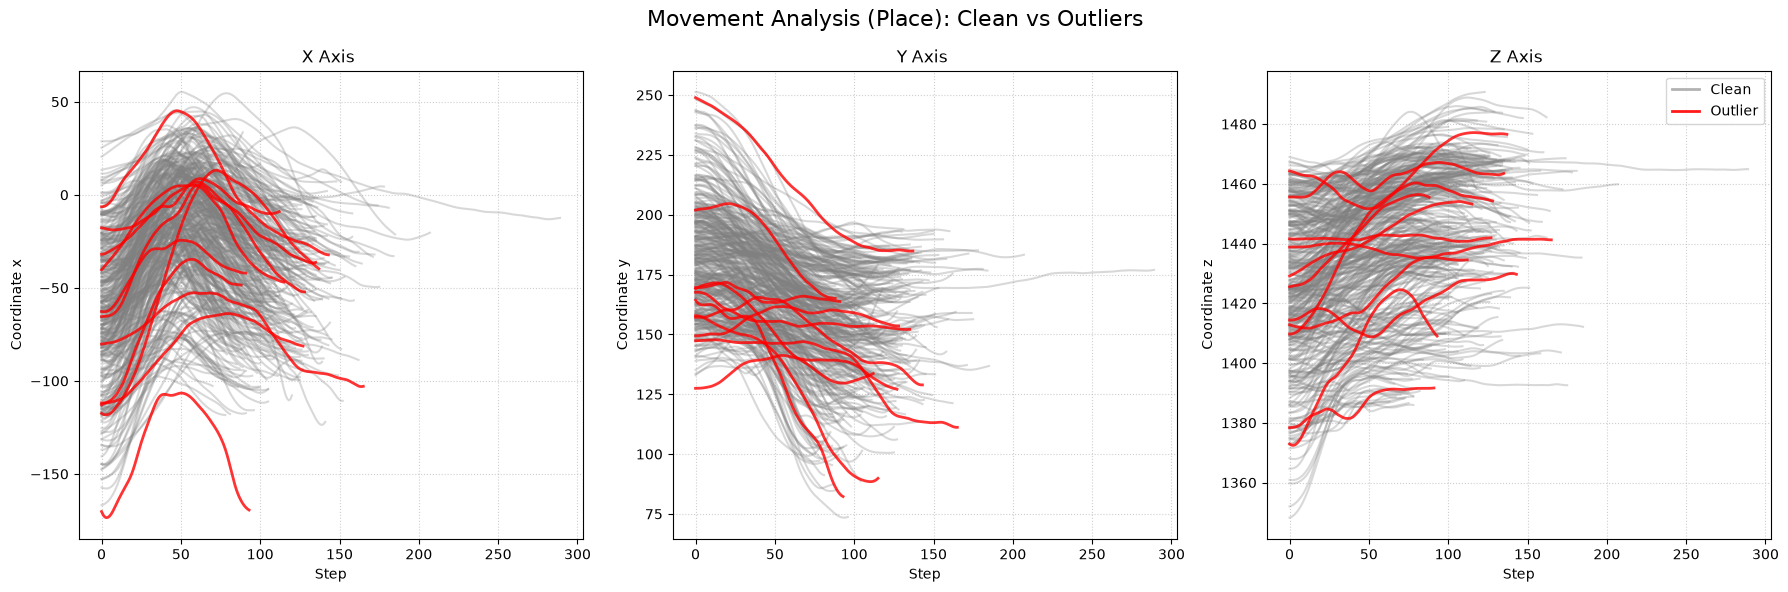

A desenhar trajetórias do Cotovelo...


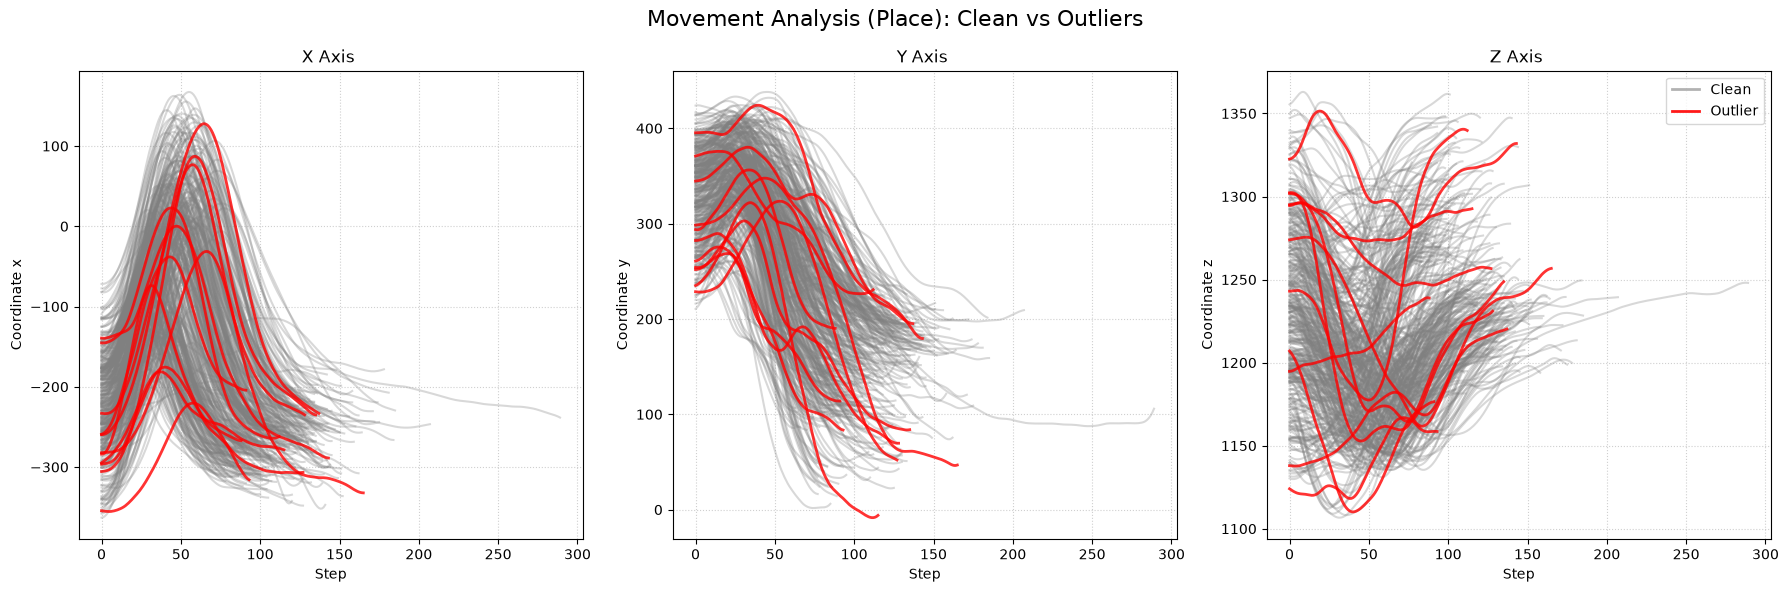

A desenhar trajetórias do Pulso...


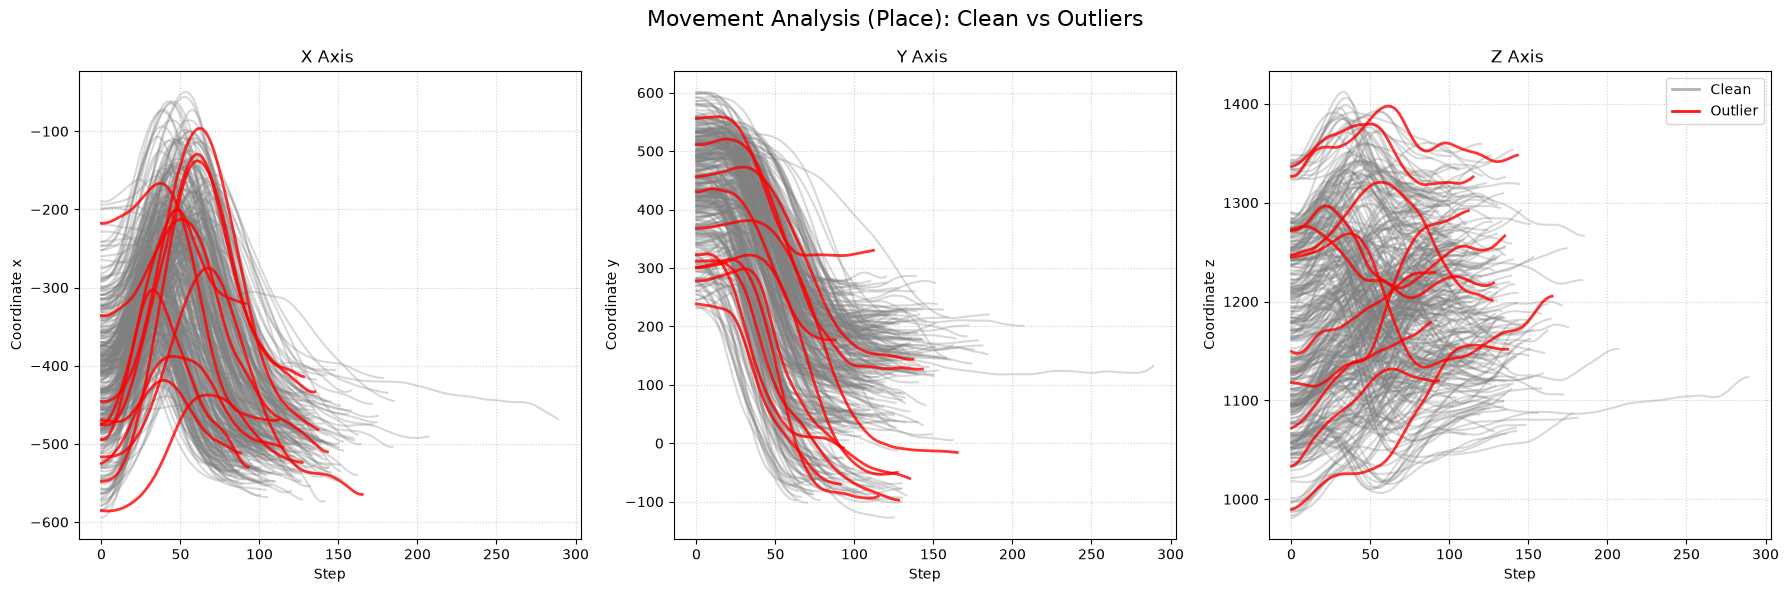

In [22]:
# 1. Ver as trajetórias do Ombro (Índices 0, 1, 2)
print("A desenhar trajetórias do Ombro...")
plot_movement_data(X_movement_clean[:, :, 0:3], X_movement_outliers[:, :, 0:3], TARGET_MOVEMENT)

# 2. Ver as trajetórias do Cotovelo (Índices 3, 4, 5)
print("A desenhar trajetórias do Cotovelo...")
plot_movement_data(X_movement_clean[:, :, 3:6], X_movement_outliers[:, :, 3:6], TARGET_MOVEMENT)

# 3. Ver as trajetórias do Pulso/Mão (Índices 6, 7, 8)
print("A desenhar trajetórias do Pulso...")
plot_movement_data(X_movement_clean[:, :, 6:9], X_movement_outliers[:, :, 6:9], TARGET_MOVEMENT)